In [1]:
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_fig = os.path.join(pth, 'figures', 'mesencoder')
pth_out = os.path.join(pth_data, 'results', 'classifier')

In [3]:
celltypes_train = [
    'Epiblast',
    'Posterior Epiblast',
    'Lateral Plate Mesoderm',
    'Neuromesodermal Progenitor',
    'Presomitic Mesoderm',
    'Premigratory Neural Crest',
    'Migratory Neural Crest',
    'Neuroglial Progenitors',
    'Cranial Mesenchyme']

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata = adata[adata.obs.celltype.isin(celltypes_train)].copy()
adata

AnnData object with n_obs × n_vars = 13029 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [5]:
src_labels = {
    'GSE162534'         : 'Branch1',
    'GSE229103'         : 'Branch2',
    'rRNAModifications' : 'Branch2'}

In [6]:
# branch labels
adata.obs['branch'] = adata.obs.source.map(src_labels)
adata.obs.branch.value_counts()

branch
Branch1    7073
Branch2    5956
Name: count, dtype: int64

In [7]:
# train classifier (logistic regression)
X, y = adata.obs[src_labels.keys()].values, adata.obs.branch.values
X = StandardScaler(with_mean = False).fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size = .2, random_state = 1, stratify = y)
logreg = LogisticRegression(penalty = None).fit(X_train, y_train)

# save model (coefficients)
df = pd.Series(logreg.coef_[0],
               index = src_labels.keys(),
               name = 'beta')
df.loc['intercept_'] = logreg.intercept_[0]
df.to_csv(os.path.join(pth_out, 'logreg.csv'))

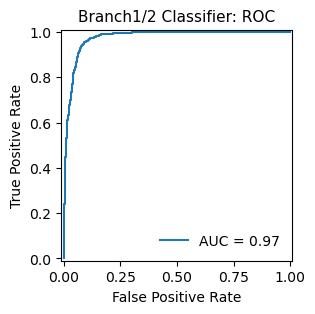

In [18]:
# validation split
pos_label, ix = 'Branch2', logreg.classes_
p_val = logreg.predict_proba(X_val)[:, ix == pos_label]
fpr, tpr, _ = roc_curve(y_val, p_val, pos_label = pos_label)
auc = roc_auc_score(y_val, p_val)

# plot performance (ROC)
fig, ax = plt.subplots(1, 1, figsize = (3, 3))
RocCurveDisplay(fpr = fpr, tpr = tpr, roc_auc = auc).plot(ax = ax)
ax.legend(loc = 4).set_frame_on(False)
ax.set_title('Branch1/2 Classifier: ROC', size = 11)
fn = os.path.join(pth_fig, 'classifier.pdf')
plt.savefig(fn, bbox_inches = 'tight')